# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

# Compare Timing

For each board size, benchmark the same 20 pre-generated boards with five timing repeats and three iterations per repeat. Report the median runtime per board in microseconds. The `conflicts_jit()` function is called once before timing, so its first-call compilation cost is excluded; every timed call uses the already-compiled `int64` signature.

`conflicts_naive()` checks pairs with nested loops (and scans rows), so its work grows as $O(n^2)$. `conflicts()` counts queens in each row and diagonal in one pass using arrays of size proportional to $n$, so it is $O(n)$. `conflicts_jit()` uses the same linear algorithm, but Numba compiles it to native machine code and avoids Python interpreter overhead on later calls. This typically makes it fastest, although the exact speedup depends on the machine and can be less noticeable for small boards.

The first plot uses a logarithmic time axis to show all three methods; the second uses a linear axis to compare the two linear-time methods.

In [5]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [6]:
import timeit

# Compile the int64 signature before any timed calls.
conflicts_jit(random_board(8))

board_count = 20
timing_repeats = 5
iterations = 3
x = []
naive_times = []
linear_times = []
jit_times = []
for i in [8] + list(range(50, 500, 50)):
    boards = [random_board(i) for _ in range(board_count)]
    assert all(
        conflicts_naive(board) == conflicts(board) == conflicts_jit(board)
        for board in boards
    )

    naive_samples = timeit.repeat(
        lambda: [conflicts_naive(board) for board in boards],
        repeat=timing_repeats, number=iterations,
    )
    linear_samples = timeit.repeat(
        lambda: [conflicts(board) for board in boards],
        repeat=timing_repeats, number=iterations,
    )
    jit_samples = timeit.repeat(
        lambda: [conflicts_jit(board) for board in boards],
        repeat=timing_repeats, number=iterations,
    )
    x.append(i)
    calls_per_sample = board_count * iterations
    naive_times.append(np.median(naive_samples) / calls_per_sample * 1e6)
    linear_times.append(np.median(linear_samples) / calls_per_sample * 1e6)
    jit_times.append(np.median(jit_samples) / calls_per_sample * 1e6)

print("Median runtime per board (microseconds)")
print(f"{'n':>4} {'naive':>12} {'linear':>12} {'Numba JIT':>12}")
for n, naive, linear, jit in zip(x, naive_times, linear_times, jit_times):
    print(f"{n:4d} {naive:12.3f} {linear:12.3f} {jit:12.3f}")

Median runtime per board (microseconds)
   n        naive       linear    Numba JIT
   8       34.962        7.495        0.490
  50      363.213       39.518        1.038
 100     1276.802       54.703        1.327
 150     2543.545       90.403        1.312
 200     4069.185      115.152        1.802
 250     6281.367      142.725        2.107
 300     8993.040      185.787        2.417
 350    12731.312      206.282        2.888
 400    16093.910      236.228        3.133
 450    19273.372      269.882        3.493


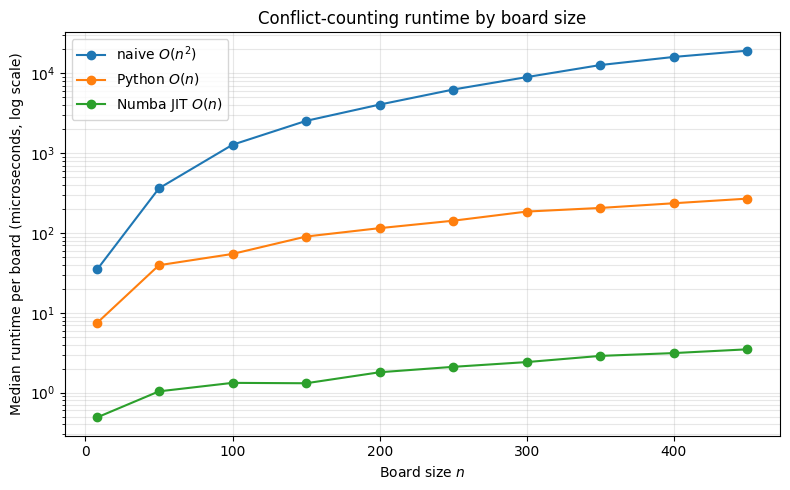

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(x, naive_times, marker="o", label="naive $O(n^2)$")
plt.plot(x, linear_times, marker="o", label="Python $O(n)$")
plt.plot(x, jit_times, marker="o", label="Numba JIT $O(n)$")
plt.yscale("log")
plt.xlabel("Board size $n$")
plt.ylabel("Median runtime per board (microseconds, log scale)")
plt.title("Conflict-counting runtime by board size")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

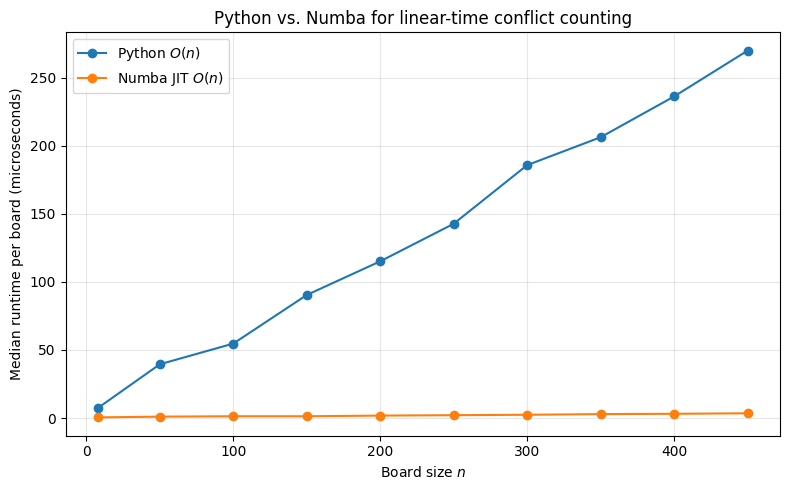

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(x, linear_times, marker="o", label="Python $O(n)$")
plt.plot(x, jit_times, marker="o", label="Numba JIT $O(n)$")
plt.xlabel("Board size $n$")
plt.ylabel("Median runtime per board (microseconds)")
plt.title("Python vs. Numba for linear-time conflict counting")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()